### Question 1

In [ ]:
# If needed, run this in a separate notebook cell:
# %pip install numpy matplotlib scikit-learn

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier

from itertools import combinations
from collections import Counter



In [ ]:
ROLL_NUMBER = "M26MER005"

digits = "".join(
    character for character in ROLL_NUMBER
    if character.isdigit()
)

if not digits:
    raise ValueError("The roll number must contain numeric characters.")

SEED = int(digits)
rng = np.random.default_rng(SEED)

print("Numeric characters:", digits)
print("Random seed:", SEED)

Numeric characters: 26005
Random seed: 26005


In [ ]:
faces = fetch_olivetti_faces()

images = faces.images
X = images.reshape(len(images), -1)
y = faces.target

print("Images shape:", images.shape)
print("Flattened data shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of identities:", len(np.unique(y)))
print("Pixel features per image:", X.shape[1])

Images shape: (400, 64, 64)
Flattened data shape: (400, 4096)
Labels shape: (400,)
Number of identities: 40
Pixel features per image: 4096


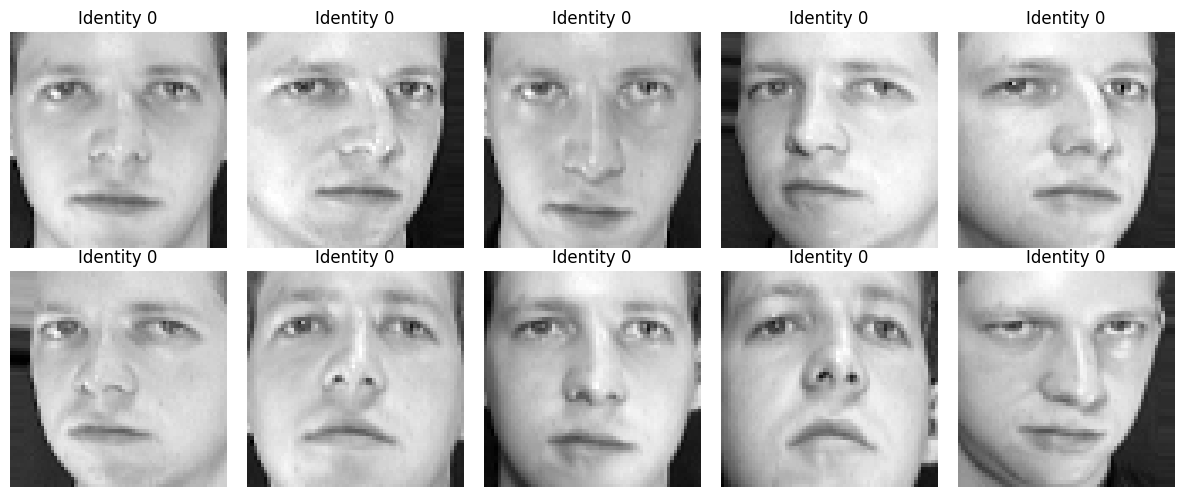

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Identity {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_indices = []
val_indices = []
test_indices = []

for identity in np.unique(y):
    identity_indices = np.flatnonzero(y == identity)

    # Each identity has exactly 10 images.
    assert len(identity_indices) == 10

    shuffled = rng.permutation(identity_indices)

    train_indices.extend(shuffled[:6])
    val_indices.extend(shuffled[6:8])
    test_indices.extend(shuffled[8:10])

train_indices = np.array(train_indices, dtype=int)
val_indices = np.array(val_indices, dtype=int)
test_indices = np.array(test_indices, dtype=int)

# Save the exact split for reuse.
np.savez(
    "olivetti_face_split.npz",
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,
    seed=SEED
)

X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (240, 4096) (240,)
Validation: (80, 4096) (80,)
Test: (80, 4096) (80,)


In [ ]:
for identity in np.unique(y):
    n_train = np.sum(y_train == identity)
    n_val = np.sum(y_val == identity)
    n_test = np.sum(y_test == identity)

    assert (n_train, n_val, n_test) == (6, 2, 2)



In [ ]:
depth_values = [2, 4, 8, 16, None]
leaf_values = [1, 2, 4]

tree_results = []
candidate_trees = {}

for depth in depth_values:
    for min_leaf in leaf_values:

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=SEED
        )

        model.fit(X_train, y_train)

        train_acc = model.score(X_train, y_train)
        val_acc = model.score(X_val, y_val)

        tree_results.append({
            "max_depth": depth,
            "min_samples_leaf": min_leaf,
            "train_accuracy": train_acc,
            "validation_accuracy": val_acc,
            "leaves": model.get_n_leaves()
        })

        candidate_trees[(depth, min_leaf)] = model


best_result = max(
    tree_results,
    key=lambda r: (
        r["validation_accuracy"],
        -(r["max_depth"] if r["max_depth"] is not None else 10**9),
        -r["min_samples_leaf"]
    )
)

best_key = (
    best_result["max_depth"],
    best_result["min_samples_leaf"]
)

frozen_tree = candidate_trees[best_key]

print("Selected max_depth:", best_key[0])
print("Selected min_samples_leaf:", best_key[1])
print("Validation accuracy:", best_result["validation_accuracy"])

Selected max_depth: None
Selected min_samples_leaf: 1
Validation accuracy: 0.6125


In [ ]:
train_acc = frozen_tree.score(X_train, y_train)
val_acc = frozen_tree.score(X_val, y_val)
test_acc = frozen_tree.score(X_test, y_test)

# Count training examples reaching each leaf.
leaf_ids = frozen_tree.apply(X_train)

leaf_counts = np.unique(leaf_ids, return_counts=True)[1]

number_of_leaves = frozen_tree.get_n_leaves()
mean_samples_per_leaf = leaf_counts.mean()
fraction_singleton_leaves = np.mean(leaf_counts == 1)

print(f"Training accuracy: {train_acc:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Number of leaves: {number_of_leaves}")
print(f"Mean training samples per leaf: {mean_samples_per_leaf:.4f}")
print(
    "Fraction of leaves with exactly one training example:",
    f"{fraction_singleton_leaves:.4f}"
)

Training accuracy: 1.0000
Validation accuracy: 0.6125
Test accuracy: 0.4625
Number of leaves: 46
Mean training samples per leaf: 5.2174
Fraction of leaves with exactly one training example: 0.1304


### Question 2

In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

# Nine samples, three classes, one numeric feature.
X_toy = np.array([
    [0], [1], [2],
    [3], [4], [5],
    [6], [7], [8]
], dtype=float)

y_toy = np.array([
        0, 0, 0,
    1, 1, 1,
    2, 2, 2
])

K_toy = len(np.unique(y_toy))
n_toy = len(y_toy)

# Equal initial weights.
w_initial = np.ones(n_toy) / n_toy

print("Number of samples:", n_toy)
print("Classes:", np.unique(y_toy))
print("Initial weights:", w_initial)
print("Sum of weights:", w_initial.sum())

Number of samples: 9
Classes: [0 1 2]
Initial weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Sum of weights: 1.0


In [ ]:
toy_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

toy_learner.fit(
    X_toy,
    y_toy,
    sample_weight=w_initial
)

toy_predictions = toy_learner.predict(X_toy)

incorrect = toy_predictions != y_toy
weighted_error = np.sum(w_initial * incorrect)

# SAMME requires error < 1 - 1/K.
error_threshold = 1 - 1 / K_toy

if weighted_error >= error_threshold:
    raise RuntimeError(
        "Toy weak learner is not better than random multiclass prediction."
    )

if weighted_error == 0:
    alpha = np.inf
    updated_weights = w_initial.copy()
else:
    alpha = (
        np.log((1 - weighted_error) / weighted_error)
        + np.log(K_toy - 1)
    )

    updated_weights = w_initial * np.exp(alpha * incorrect)
    updated_weights /= updated_weights.sum()

print("Initial weights:")
print(np.round(w_initial, 4))

print("\nTrue labels:")
print(y_toy)

print("\nWeak learner predictions:")
print(toy_predictions)

print("\nIncorrect prediction flags:")
print(incorrect)

print("\nWeighted error:", weighted_error)
print("Random-guessing error threshold:", error_threshold)
print("Learner weight alpha:", alpha)

print("\nUpdated normalised weights:")
print(np.round(updated_weights, 4))
print("Updated weight sum:", updated_weights.sum())

Initial weights:
[0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]

True labels:
[0 0 0 1 1 1 2 2 2]

Weak learner predictions:
[0 0 0 1 1 1 1 1 1]

Incorrect prediction flags:
[False False False False False False  True  True  True]

Weighted error: 0.3333333333333333
Random-guessing error threshold: 0.6666666666666667
Learner weight alpha: 1.3862943611198908

Updated normalised weights:
[0.0556 0.0556 0.0556 0.0556 0.0556 0.0556 0.2222 0.2222 0.2222]
Updated weight sum: 1.0


In [ ]:
import time
from sklearn.tree import DecisionTreeClassifier


class SAMMEFromScratch:
    """
    Multiclass SAMME AdaBoost implementation.

    Weak learners are DecisionTreeClassifier models.
    No sklearn AdaBoost or bagging ensemble is used.
    """

    def __init__(self, max_depth=1, n_estimators=50, random_state=42):
        self.max_depth = max_depth
        self.n_estimators = n_estimators
        self.random_state = random_state

        self.estimators_ = []
        self.estimator_weights_ = []
        self.errors_ = []
        self.weight_history_ = []
        self.prediction_history_ = []
        self.max_weight_history_ = []
        self.top10_weight_history_ = []
        self.stopped_reason_ = None

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)

        n = len(y)
        self.classes_ = np.unique(y)
        K = len(self.classes_)

        if K < 2:
            raise ValueError("SAMME requires at least two classes.")

        # Use an equal distribution over the training samples.
        sample_weights = np.ones(n, dtype=float) / n

        self.estimators_ = []
        self.estimator_weights_ = []
        self.errors_ = []
        self.weight_history_ = [sample_weights.copy()]
        self.prediction_history_ = []
        self.max_weight_history_ = []
        self.top10_weight_history_ = []
        self.stopped_reason_ = None

        # Better than random multiclass prediction.
        error_threshold = 1 - 1 / K

        for t in range(self.n_estimators):
            learner = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=self.random_state + t
            )

            learner.fit(
                X,
                y,
                sample_weight=sample_weights
            )

            predictions = learner.predict(X)
            incorrect = predictions != y

            error = float(
                np.sum(sample_weights * incorrect)
                / np.sum(sample_weights)
            )

            # Explicitly reject a learner that is no better than
            # random multiclass prediction.
            if error >= error_threshold:
                self.stopped_reason_ = (
                    "Weak learner error was not below "
                    "the multiclass random-guessing threshold."
                )
                break

            # A perfect learner has an infinite theoretical SAMME weight.
            # Store a large finite weight for numerical stability, then stop.
            if error <= 0:
                alpha = 50.0

                self.estimators_.append(learner)
                self.estimator_weights_.append(alpha)
                self.errors_.append(error)
                self.prediction_history_.append(predictions.copy())

                self.max_weight_history_.append(
                    float(sample_weights.max())
                )
                self.top10_weight_history_.append(
                    float(np.sort(sample_weights)[-min(10, n):].sum())
                )

                self.stopped_reason_ = "Perfect weak learner reached."
                break

            alpha = (
                np.log((1 - error) / error)
                + np.log(K - 1)
            )

            # Record this learner and its weighted training error.
            self.estimators_.append(learner)
            self.estimator_weights_.append(float(alpha))
            self.errors_.append(error)
            self.prediction_history_.append(predictions.copy())

            # SAMME update: multiply incorrect examples by exp(alpha).
            sample_weights *= np.exp(alpha * incorrect)

            # Normalise to a probability distribution.
            weight_sum = sample_weights.sum()
            if not np.isfinite(weight_sum) or weight_sum <= 0:
                raise FloatingPointError("Invalid sample-weight distribution.")

            sample_weights /= weight_sum

            # Save post-update distribution statistics.
            self.weight_history_.append(sample_weights.copy())
            self.max_weight_history_.append(
                float(sample_weights.max())
            )
            self.top10_weight_history_.append(
                float(np.sort(sample_weights)[-min(10, n):].sum())
            )

        if not self.estimators_:
            raise RuntimeError(
                "No acceptable weak learner was found. "
                + str(self.stopped_reason_)
            )

        return self

    def decision_function(self, X):
        X = np.asarray(X)
        scores = np.zeros((len(X), len(self.classes_)), dtype=float)

        class_to_index = {
            label: index
            for index, label in enumerate(self.classes_)
        }

        for learner, alpha in zip(
            self.estimators_,
            self.estimator_weights_
        ):
            predictions = learner.predict(X)

            for label in self.classes_:
                scores[:, class_to_index[label]] += (
                    alpha * (predictions == label)
                )

        return scores

    def predict(self, X):
        scores = self.decision_function(X)
        return self.classes_[np.argmax(scores, axis=1)]

    def predict_proba(self, X):
        """
        Assignment-defined normalised weighted vote:
        q_k(x) = S_k(x) / sum_t alpha_t.
        """
        scores = self.decision_function(X)
        total_alpha = np.sum(self.estimator_weights_)

        if total_alpha <= 0:
            raise RuntimeError("Total learner weight must be positive.")

        return scores / total_alpha

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

In [ ]:
boosting_depths = [1, 2, 3, 4]
boosting_rounds = [10, 25, 50, 100]

boosting_results = []
boosting_models = {}
boosting_times = {}

for depth in boosting_depths:
    for rounds in boosting_rounds:
        model = SAMMEFromScratch(
            max_depth=depth,
            n_estimators=rounds,
            random_state=SEED
        )

        start_time = time.perf_counter()

        model.fit(X_train, y_train)

        elapsed = time.perf_counter() - start_time

        train_acc = model.score(X_train, y_train)
        val_acc = model.score(X_val, y_val)

        key = (depth, rounds)

        boosting_models[key] = model
        boosting_times[key] = elapsed

        boosting_results.append({
            "depth": depth,
            "requested_rounds": rounds,
            "actual_rounds": len(model.estimators_),
            "train_accuracy": train_acc,
            "validation_accuracy": val_acc,
            "training_time_seconds": elapsed,
            "stop_reason": model.stopped_reason_
        })

        print(
            f"Depth={depth:2d}, requested={rounds:3d}, "
            f"actual={len(model.estimators_):3d}, "
            f"train={train_acc:.4f}, val={val_acc:.4f}, "
            f"time={elapsed:.2f}s"
        )

Depth= 1, requested= 10, actual= 10, train=0.0500, val=0.0375, time=1.13s
Depth= 1, requested= 25, actual= 25, train=0.0917, val=0.0750, time=3.07s
Depth= 1, requested= 50, actual= 50, train=0.2583, val=0.1875, time=6.20s
Depth= 1, requested=100, actual=100, train=0.1750, val=0.1250, time=17.09s
Depth= 2, requested= 10, actual= 10, train=0.0958, val=0.0625, time=2.67s
Depth= 2, requested= 25, actual= 25, train=0.2833, val=0.1500, time=5.85s
Depth= 2, requested= 50, actual= 50, train=0.2792, val=0.1625, time=11.92s
Depth= 2, requested=100, actual=100, train=0.3458, val=0.1250, time=24.54s
Depth= 3, requested= 10, actual= 10, train=0.2083, val=0.1125, time=3.89s
Depth= 3, requested= 25, actual= 25, train=0.3083, val=0.1875, time=8.55s
Depth= 3, requested= 50, actual= 50, train=0.7458, val=0.4000, time=19.39s
Depth= 3, requested=100, actual=100, train=0.8542, val=0.4000, time=34.82s
Depth= 4, requested= 10, actual= 10, train=0.2292, val=0.1375, time=4.56s
Depth= 4, requested= 25, actual= 

In [ ]:
best_boosting_result = max(
    boosting_results,
    key=lambda r: (
        r["validation_accuracy"],
        -r["depth"],
        -r["requested_rounds"]
    )
)

best_boosting_key = (
    best_boosting_result["depth"],
    best_boosting_result["requested_rounds"]
)

frozen_boosting = boosting_models[best_boosting_key]

print("Selected depth:", best_boosting_key[0])
print("Selected requested rounds:", best_boosting_key[1])
print("Actual rounds:", len(frozen_boosting.estimators_))
print(
    "Validation accuracy:",
    best_boosting_result["validation_accuracy"]
)

Selected depth: 4
Selected requested rounds: 50
Actual rounds: 50
Validation accuracy: 0.475


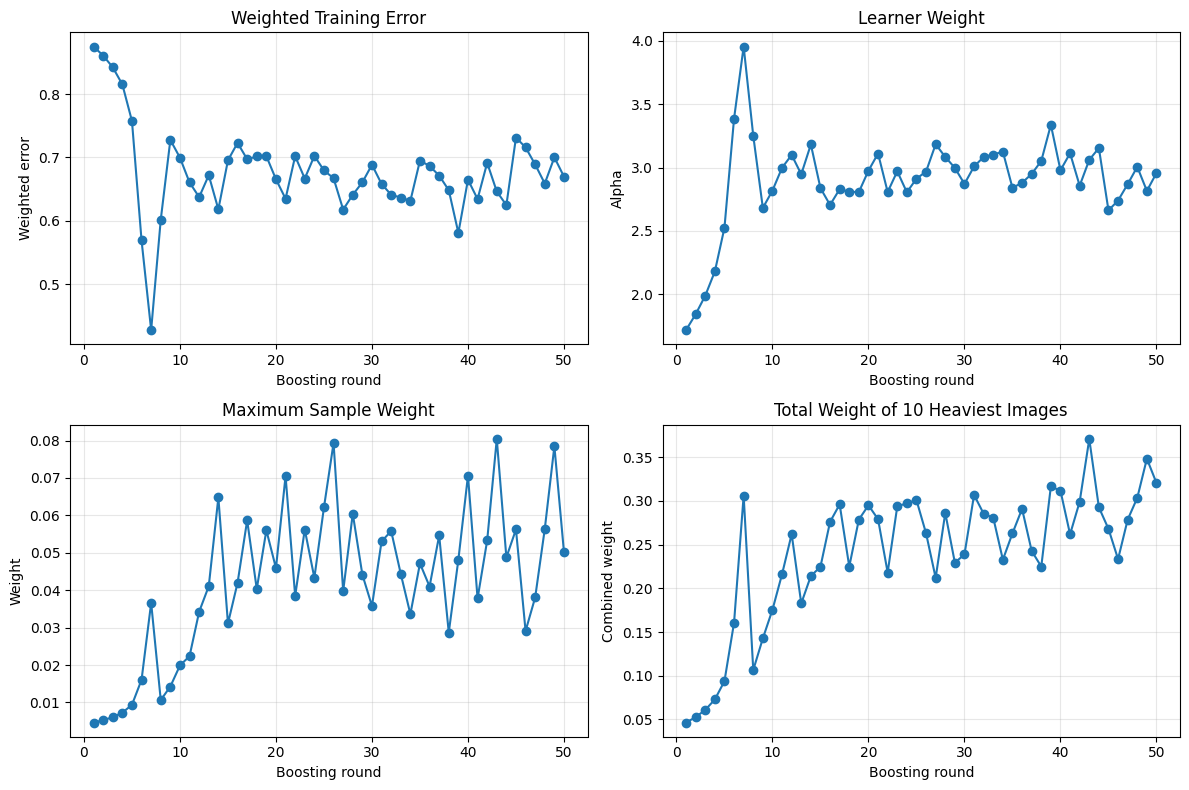

In [ ]:
round_numbers = np.arange(1, len(frozen_boosting.estimators_) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Weighted training error before each update.
axes[0, 0].plot(
    round_numbers,
    frozen_boosting.errors_,
    marker="o"
)
axes[0, 0].set_title("Weighted Training Error")
axes[0, 0].set_xlabel("Boosting round")
axes[0, 0].set_ylabel("Weighted error")

# 2. Learner weights alpha_t.
axes[0, 1].plot(
    round_numbers,
    frozen_boosting.estimator_weights_,
    marker="o"
)
axes[0, 1].set_title("Learner Weight")
axes[0, 1].set_xlabel("Boosting round")
axes[0, 1].set_ylabel("Alpha")

# 3. Maximum post-update sample weight.
axes[1, 0].plot(
    round_numbers,
    frozen_boosting.max_weight_history_,
    marker="o"
)
axes[1, 0].set_title("Maximum Sample Weight")
axes[1, 0].set_xlabel("Boosting round")
axes[1, 0].set_ylabel("Weight")

# 4. Total weight of the ten heaviest examples.
axes[1, 1].plot(
    round_numbers,
    frozen_boosting.top10_weight_history_,
    marker="o"
)
axes[1, 1].set_title("Total Weight of 10 Heaviest Images")
axes[1, 1].set_xlabel("Boosting round")
axes[1, 1].set_ylabel("Combined weight")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
class BaggingFromScratch:
    def __init__(self, tree_template, n_estimators=50, random_state=42):
        self.tree_template = tree_template
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.estimators_ = []

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)

        rng = np.random.default_rng(self.random_state)
        n = len(y)

        self.estimators_ = []
        self.bootstrap_indices_ = []

        for _ in range(self.n_estimators):
            # Sample n examples with replacement.
            indices = rng.choice(n, size=n, replace=True)

            tree = DecisionTreeClassifier(
                max_depth=self.tree_template.max_depth,
                min_samples_leaf=self.tree_template.min_samples_leaf,
                random_state=int(rng.integers(0, 2**31 - 1))
            )

            tree.fit(X[indices], y[indices])

            self.estimators_.append(tree)
            self.bootstrap_indices_.append(indices)

        return self

    def vote_counts(self, X):
        X = np.asarray(X)
        classes = self.estimators_[0].classes_
        counts = np.zeros((len(X), len(classes)), dtype=int)

        class_to_index = {
            label: i for i, label in enumerate(classes)
        }

        for tree in self.estimators_:
            predictions = tree.predict(X)

            for label in classes:
                counts[:, class_to_index[label]] += (
                    predictions == label
                )

        return classes, counts

    def predict(self, X):
        classes, counts = self.vote_counts(X)
        return classes[np.argmax(counts, axis=1)]

    def predict_confidence(self, X):
        _, counts = self.vote_counts(X)
        return counts.max(axis=1) / len(self.estimators_)

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

In [ ]:
comparison_rows = []
comparison_bagging_models = {}
comparison_boosting_models = {}

# Use the frozen baseline's parameters for every bagged tree.
tree_template = DecisionTreeClassifier(
    max_depth=best_key[0],
    min_samples_leaf=best_key[1],
    random_state=SEED
)

selected_boosting_depth = best_boosting_key[0]

for B in [25, 50, 100]:

    # Bagging
    bagger = BaggingFromScratch(
        tree_template=tree_template,
        n_estimators=B,
        random_state=SEED
    )

    start = time.perf_counter()
    bagger.fit(X_train, y_train)
    bag_time = time.perf_counter() - start

    comparison_bagging_models[B] = bagger

    comparison_rows.append({
        "method": "Bagging",
        "learners": B,
        "train_accuracy": bagger.score(X_train, y_train),
        "validation_accuracy": bagger.score(X_val, y_val),
        "clean_test_accuracy": bagger.score(X_test, y_test),
        "training_time_seconds": bag_time
    })

    # Boosting: same selected depth, varying requested rounds.
    booster = SAMMEFromScratch(
        max_depth=selected_boosting_depth,
        n_estimators=B,
        random_state=SEED
    )

    start = time.perf_counter()
    booster.fit(X_train, y_train)
    boost_time = time.perf_counter() - start

    comparison_boosting_models[B] = booster

    comparison_rows.append({
        "method": "Boosting",
        "learners": B,
        "train_accuracy": booster.score(X_train, y_train),
        "validation_accuracy": booster.score(X_val, y_val),
        "clean_test_accuracy": booster.score(X_test, y_test),
        "training_time_seconds": boost_time
    })

for row in comparison_rows:
    print(row)

{'method': 'Bagging', 'learners': 25, 'train_accuracy': np.float64(1.0), 'validation_accuracy': np.float64(0.8), 'clean_test_accuracy': np.float64(0.8375), 'training_time_seconds': 39.92269119000002}
{'method': 'Boosting', 'learners': 25, 'train_accuracy': np.float64(0.4625), 'validation_accuracy': np.float64(0.3125), 'clean_test_accuracy': np.float64(0.2), 'training_time_seconds': 11.596385627000018}
{'method': 'Bagging', 'learners': 50, 'train_accuracy': np.float64(1.0), 'validation_accuracy': np.float64(0.875), 'clean_test_accuracy': np.float64(0.8375), 'training_time_seconds': 77.29223257299998}
{'method': 'Boosting', 'learners': 50, 'train_accuracy': np.float64(0.9375), 'validation_accuracy': np.float64(0.475), 'clean_test_accuracy': np.float64(0.3625), 'training_time_seconds': 24.03050439699996}
{'method': 'Bagging', 'learners': 100, 'train_accuracy': np.float64(1.0), 'validation_accuracy': np.float64(0.8875), 'clean_test_accuracy': np.float64(0.8625), 'training_time_seconds': 15

Training-set index: 142
Original dataset index: 238
True identity: 23
Final recorded weight: 0.050152398180009106


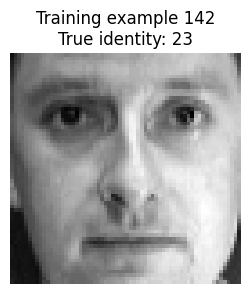

Round | Prediction | Correct?
    1 |          0 | No
    2 |          1 | No
    3 |          2 | No
    4 |          3 | No
    5 |          4 | No
    6 |         15 | No
    7 |         23 | Yes
    8 |         16 | No
    9 |          2 | No
   10 |          3 | No
   11 |         23 | Yes
   12 |          8 | No
   13 |          4 | No
   14 |          1 | No
   15 |         20 | No
   16 |          2 | No
   17 |         10 | No
   18 |         24 | No
   19 |          1 | No
   20 |         30 | No
   21 |         29 | No
   22 |         15 | No
   23 |         23 | Yes
   24 |         12 | No
   25 |          2 | No
   26 |         39 | No
   27 |          3 | No
   28 |          4 | No
   29 |         22 | No
   30 |         16 | No
   31 |         23 | Yes
   32 |         25 | No
   33 |          2 | No
   34 |          3 | No
   35 |         26 | No
   36 |          4 | No
   37 |         22 | No
   38 |         23 | Yes
   39 |         20 | No
   40 |          2 | No
   41

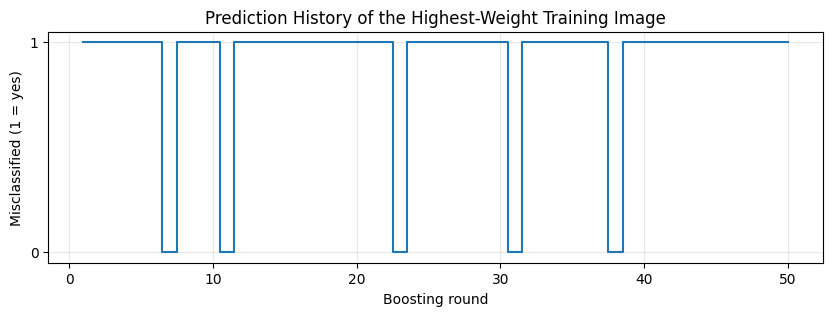

In [ ]:
# Use the selected boosting model.
weight_history = np.asarray(frozen_boosting.weight_history_)

final_weights = weight_history[-1]
difficult_index = int(np.argmax(final_weights))

print("Training-set index:", difficult_index)
print("Original dataset index:", train_indices[difficult_index])
print("True identity:", y_train[difficult_index])
print("Final recorded weight:", final_weights[difficult_index])

# Inspect the image.
plt.figure(figsize=(3, 3))
plt.imshow(
    X_train[difficult_index].reshape(64, 64),
    cmap="gray"
)
plt.title(
    f"Training example {difficult_index}\n"
    f"True identity: {y_train[difficult_index]}"
)
plt.axis("off")
plt.show()

# Prediction history across accepted boosting learners.
history_predictions = np.array([
    pred[difficult_index]
    for pred in frozen_boosting.prediction_history_
])

history_wrong = history_predictions != y_train[difficult_index]

print("Round | Prediction | Correct?")
for round_id, (prediction, wrong) in enumerate(
    zip(history_predictions, history_wrong), start=1
):
    print(
        f"{round_id:5d} | {prediction:10d} | "
        f"{'No' if wrong else 'Yes'}"
    )

plt.figure(figsize=(10, 3))
plt.step(
    np.arange(1, len(history_predictions) + 1),
    history_wrong.astype(int),
    where="mid"
)
plt.xlabel("Boosting round")
plt.ylabel("Misclassified (1 = yes)")
plt.title("Prediction History of the Highest-Weight Training Image")
plt.yticks([0, 1])
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Reuse the full Q1(c) candidate grid for final selection.
bagging_grid = [1, 5, 10, 25, 50, 100, 200]
bagging_validation_models = {}

for B in bagging_grid:
    if B in comparison_bagging_models:
        # Reuse models already trained with these ensemble sizes.
        bagger = comparison_bagging_models[B]
    else:
        bagger = BaggingFromScratch(
            tree_template=tree_template,
            n_estimators=B,
            random_state=SEED
        )
        bagger.fit(X_train, y_train)

    bagging_validation_models[B] = bagger

final_B = max(
    bagging_grid,
    key=lambda B: (
        bagging_validation_models[B].score(X_val, y_val),
        -B
    )
)

final_bagger = bagging_validation_models[final_B]

print("Selected bagging ensemble size:", final_B)
print("Validation accuracy:", final_bagger.score(X_val, y_val))

Selected bagging ensemble size: 200
Validation accuracy: 0.9


In [ ]:
# The original X values are flattened 64 x 64 images.
X_test_masked = X_test.reshape(-1, 64, 64).copy()

# Zero rows 24–39 and columns 24–39.
X_test_masked[:, 24:40, 24:40] = 0

X_test_masked = X_test_masked.reshape(-1, 4096)

assert X_test_masked.shape == X_test.shape

print("Clean test shape:", X_test.shape)
print("Masked test shape:", X_test_masked.shape)

Clean test shape: (80, 4096)
Masked test shape: (80, 4096)


In [ ]:
def evaluate_model(name, model, X_eval, y_eval, confidence_fn):
    predictions = model.predict(X_eval)
    confidence = confidence_fn(X_eval)

    return {
        "model": name,
        "accuracy": float(np.mean(predictions == y_eval)),
        "mean_winning_vote_or_probability": float(
            np.mean(confidence)
        )
    }


tree_confidence = lambda X_eval: frozen_tree.predict_proba(X_eval).max(axis=1)

bagging_confidence = lambda X_eval: final_bagger.predict_confidence(X_eval)

boosting_confidence = lambda X_eval: frozen_boosting.predict_proba(X_eval).max(axis=1)

models = [
    ("Single tree", frozen_tree, tree_confidence),
    ("Bagging", final_bagger, bagging_confidence),
    ("Boosting", frozen_boosting, boosting_confidence)
]

evaluation_rows = []

for dataset_name, X_eval in [
    ("Clean", X_test),
    ("Masked", X_test_masked)
]:
    for name, model, confidence_fn in models:
        row = evaluate_model(
            name, model, X_eval, y_test, confidence_fn
        )
        row["dataset"] = dataset_name
        evaluation_rows.append(row)

for row in evaluation_rows:
    print(row)

{'model': 'Single tree', 'accuracy': 0.4625, 'mean_winning_vote_or_probability': 1.0, 'dataset': 'Clean'}
{'model': 'Bagging', 'accuracy': 0.8875, 'mean_winning_vote_or_probability': 0.3956875, 'dataset': 'Clean'}
{'model': 'Boosting', 'accuracy': 0.3625, 'mean_winning_vote_or_probability': 0.12724286241214935, 'dataset': 'Clean'}
{'model': 'Single tree', 'accuracy': 0.4625, 'mean_winning_vote_or_probability': 1.0, 'dataset': 'Masked'}
{'model': 'Bagging', 'accuracy': 0.8, 'mean_winning_vote_or_probability': 0.29175, 'dataset': 'Masked'}
{'model': 'Boosting', 'accuracy': 0.225, 'mean_winning_vote_or_probability': 0.14152797339820794, 'dataset': 'Masked'}


Test index: 0
Original dataset index: 2
True identity: 0

Bagging:
Clean prediction: 7
Masked prediction: 7

Boosting:
Clean prediction: 2
Masked prediction: 3


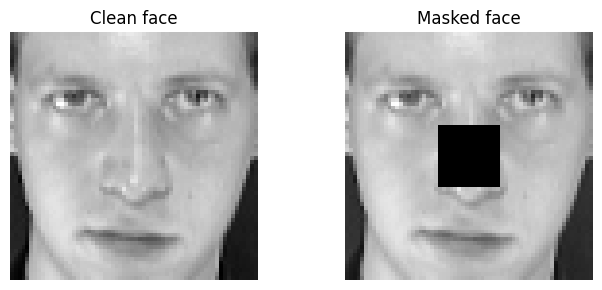

In [ ]:
tree_clean = frozen_tree.predict(X_test)
tree_masked = frozen_tree.predict(X_test_masked)

bag_clean = final_bagger.predict(X_test)
bag_masked = final_bagger.predict(X_test_masked)

boost_clean = frozen_boosting.predict(X_test)
boost_masked = frozen_boosting.predict(X_test_masked)

# Find cases where the prediction-change indicator differs.
different_response = (
    (bag_clean != bag_masked) !=
    (boost_clean != boost_masked)
)

candidates = np.flatnonzero(different_response)

if len(candidates) == 0:
    print(
        "No test face had different change/no-change behaviour. "
        "Inspect cases where bagging and boosting have different "
        "masked predictions instead."
    )
else:
    i = int(candidates[0])

    print("Test index:", i)
    print("Original dataset index:", test_indices[i])
    print("True identity:", y_test[i])

    print("\nBagging:")
    print("Clean prediction:", bag_clean[i])
    print("Masked prediction:", bag_masked[i])

    print("\nBoosting:")
    print("Clean prediction:", boost_clean[i])
    print("Masked prediction:", boost_masked[i])

    plt.figure(figsize=(7, 3))

    plt.subplot(1, 2, 1)
    plt.imshow(X_test[i].reshape(64, 64), cmap="gray")
    plt.title("Clean face")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(X_test_masked[i].reshape(64, 64), cmap="gray")
    plt.title("Masked face")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

### Question 3

In [ ]:
from sklearn.preprocessing import label_binarize
import pandas as pd
import numpy as np
import time

R = 30
N = len(y_test)
classes = np.sort(np.unique(y_train))
K = len(classes)

# Fixed one-hot target vectors for the clean test set.
Y_test_onehot = label_binarize(y_test, classes=classes)

assert len(X_test) == 80
assert Y_test_onehot.shape == (80, 40)

print("Fixed clean test images:", N)
print("Number of classes:", K)
print("One-hot target shape:", Y_test_onehot.shape)

Fixed clean test images: 80
Number of classes: 40
One-hot target shape: (80, 40)


In [ ]:
def stratified_training_bootstrap(
    X_train, y_train, rng
):
    """
    Sample six times with replacement from each identity's
    original six training examples.

    Returns 240 examples, preserving six draws per identity.
    """
    sampled_positions = []

    for identity in np.sort(np.unique(y_train)):
        positions = np.flatnonzero(y_train == identity)

        if len(positions) != 6:
            raise ValueError(
                f"Expected six original training images for {identity}; "
                f"found {len(positions)}."
            )

        draws = rng.choice(
            positions,
            size=6,
            replace=True
        )
        sampled_positions.extend(draws)

    sampled_positions = np.asarray(sampled_positions, dtype=int)

    # Shuffle the resulting dataset to avoid grouping by identity.
    sampled_positions = rng.permutation(sampled_positions)

    return (
        X_train[sampled_positions],
        y_train[sampled_positions]
    )

In [ ]:
def single_tree_class_vector(model, X):
    """
    Return class probability vectors in the global class order.
    """
    raw = model.predict_proba(X)
    aligned = np.zeros((len(X), len(classes)))

    for j, label in enumerate(model.classes_):
        target_col = np.flatnonzero(classes == label)[0]
        aligned[:, target_col] = raw[:, j]

    return aligned


def bagging_class_vector(model, X):
    """
    Normalised tree vote fractions, not leaf probabilities.
    """
    model_classes, counts = model.vote_counts(X)
    aligned = np.zeros((len(X), len(classes)))

    for j, label in enumerate(model_classes):
        target_col = np.flatnonzero(classes == label)[0]
        aligned[:, target_col] = counts[:, j] / len(model.estimators_)

    return aligned


def boosting_class_vector(model, X):
    """
    Assignment-defined normalised SAMME weighted votes.
    """
    raw = model.predict_proba(X)
    aligned = np.zeros((len(X), len(classes)))

    for j, label in enumerate(model.classes_):
        target_col = np.flatnonzero(classes == label)[0]
        aligned[:, target_col] = raw[:, j]

    return aligned

In [ ]:
rng_q3 = np.random.default_rng(SEED + 3000)

selected_models = {
    "Single tree": {
        "depth": best_key[0],
        "min_leaf": best_key[1]
    },
    "Bagging": {
        "depth": best_key[0],
        "min_leaf": best_key[1],
        "B": final_B
    },
    "Boosting": {
        "depth": best_boosting_key[0],
        "rounds": best_boosting_key[1]
    }
}

# Store class vectors for every repetition.
predictions_by_model = {
    name: [] for name in selected_models
}

accuracy_by_model = {
    name: [] for name in selected_models
}

for r in range(R):
    X_resampled, y_resampled = stratified_training_bootstrap(
        X_train, y_train, rng_q3
    )

    # 1. Single tree: frozen hyperparameters.
    tree_r = DecisionTreeClassifier(
        max_depth=selected_models["Single tree"]["depth"],
        min_samples_leaf=selected_models["Single tree"]["min_leaf"],
        random_state=SEED + 10000 + r
    )
    tree_r.fit(X_resampled, y_resampled)

    p_tree = single_tree_class_vector(tree_r, X_test)
    predictions_by_model["Single tree"].append(p_tree)
    accuracy_by_model["Single tree"].append(
        np.mean(classes[np.argmax(p_tree, axis=1)] == y_test)
    )

    # 2. Bagging: same frozen tree configuration and ensemble size.
    bag_r = BaggingFromScratch(
        tree_template=DecisionTreeClassifier(
            max_depth=selected_models["Bagging"]["depth"],
            min_samples_leaf=selected_models["Bagging"]["min_leaf"]
        ),
        n_estimators=selected_models["Bagging"]["B"],
        random_state=SEED + 20000 + r
    )
    bag_r.fit(X_resampled, y_resampled)

    p_bag = bagging_class_vector(bag_r, X_test)
    predictions_by_model["Bagging"].append(p_bag)
    accuracy_by_model["Bagging"].append(
        np.mean(classes[np.argmax(p_bag, axis=1)] == y_test)
    )

    # 3. Boosting: same selected depth and requested rounds.
    boost_r = SAMMEFromScratch(
        max_depth=selected_models["Boosting"]["depth"],
        n_estimators=selected_models["Boosting"]["rounds"],
        random_state=SEED + 30000 + r
    )
    boost_r.fit(X_resampled, y_resampled)

    p_boost = boosting_class_vector(boost_r, X_test)
    predictions_by_model["Boosting"].append(p_boost)
    accuracy_by_model["Boosting"].append(
        np.mean(classes[np.argmax(p_boost, axis=1)] == y_test)
    )

    print(f"Completed repetition {r + 1}/{R}")

Completed repetition 1/30
Completed repetition 2/30
Completed repetition 3/30
Completed repetition 4/30
Completed repetition 5/30
Completed repetition 6/30
Completed repetition 7/30
Completed repetition 8/30
Completed repetition 9/30
Completed repetition 10/30
Completed repetition 11/30
Completed repetition 12/30
Completed repetition 13/30
Completed repetition 14/30
Completed repetition 15/30
Completed repetition 16/30
Completed repetition 17/30
Completed repetition 18/30
Completed repetition 19/30
Completed repetition 20/30
Completed repetition 21/30
Completed repetition 22/30
Completed repetition 23/30
Completed repetition 24/30
Completed repetition 25/30
Completed repetition 26/30
Completed repetition 27/30
Completed repetition 28/30
Completed repetition 29/30
Completed repetition 30/30


In [ ]:
def bias_variance_metrics(P, Y_onehot):
    """
    P: array of shape (R, N, K)
       Class vectors for R refits on N fixed test images.
    Y_onehot: array of shape (N, K)

    Returns measured bias squared and variance.
    """
    P = np.asarray(P, dtype=float)
    P_bar = P.mean(axis=0)

    bias_squared = np.mean(
        np.sum((P_bar - Y_onehot) ** 2, axis=1)
    )

    variance = np.mean(
        np.sum((P - P_bar[None, :, :]) ** 2, axis=2)
    )

    return float(bias_squared), float(variance)


q3a_rows = []

for name in selected_models:
    P = np.stack(predictions_by_model[name], axis=0)

    bias_sq, variance = bias_variance_metrics(P, Y_test_onehot)

    accuracies = np.asarray(accuracy_by_model[name])

    q3a_rows.append({
        "Model": name,
        "Bias squared": bias_sq,
        "Variance": variance,
        "Mean test accuracy": accuracies.mean(),
        "Std test accuracy": accuracies.std(ddof=1)
    })

q3a_table = pd.DataFrame(q3a_rows)
print(q3a_table.round(4).to_string(index=False))

      Model  Bias squared  Variance  Mean test accuracy  Std test accuracy
Single tree        0.3820    0.6614              0.4783             0.0505
    Bagging        0.5096    0.0236              0.7879             0.0366
   Boosting        0.8880    0.0213              0.2779             0.0647


In [ ]:
selected_depth = best_key[0]

if selected_depth == 2:
    shallow_depth = 1
else:
    shallow_depth = 2

if selected_depth is None:
    deep_depth = 32
else:
    deep_depth = None

depth_settings = [
    ("Shallow", shallow_depth),
    ("Selected", selected_depth),
    ("Deep", deep_depth)
]

print("Depth settings:")
for label, depth in depth_settings:
    print(label, ":", depth)

Depth settings:
Shallow : 2
Selected : None
Deep : 32


In [ ]:
depth_rng = np.random.default_rng(SEED + 4000)

depth_predictions = {}
depth_accuracies = {}

for label, depth in depth_settings:
    depth_predictions[("Single tree", label)] = []
    depth_accuracies[("Single tree", label)] = []

    depth_predictions[("Bagging-100", label)] = []
    depth_accuracies[("Bagging-100", label)] = []

for r in range(R):
    X_resampled, y_resampled = stratified_training_bootstrap(
        X_train, y_train, depth_rng
    )

    for label, depth in depth_settings:

        # Single tree at this depth.
        tree_r = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=1,
            random_state=SEED + 41000 + r
        )
        tree_r.fit(X_resampled, y_resampled)

        p_tree = single_tree_class_vector(tree_r, X_test)

        key_tree = ("Single tree", label)
        depth_predictions[key_tree].append(p_tree)
        depth_accuracies[key_tree].append(
            np.mean(classes[np.argmax(p_tree, axis=1)] == y_test)
        )

        # 100-tree bagging at the same depth.
        bag_r = BaggingFromScratch(
            tree_template=DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=1
            ),
            n_estimators=100,
            random_state=SEED + 42000 + r
        )
        bag_r.fit(X_resampled, y_resampled)

        p_bag = bagging_class_vector(bag_r, X_test)

        key_bag = ("Bagging-100", label)
        depth_predictions[key_bag].append(p_bag)
        depth_accuracies[key_bag].append(
            np.mean(classes[np.argmax(p_bag, axis=1)] == y_test)
        )

    print(f"Depth experiment: completed {r + 1}/{R}")

Depth experiment: completed 1/30
Depth experiment: completed 2/30
Depth experiment: completed 3/30
Depth experiment: completed 4/30
Depth experiment: completed 5/30
Depth experiment: completed 6/30
Depth experiment: completed 7/30
Depth experiment: completed 8/30
Depth experiment: completed 9/30
Depth experiment: completed 10/30
Depth experiment: completed 11/30
Depth experiment: completed 12/30
Depth experiment: completed 13/30
Depth experiment: completed 14/30
Depth experiment: completed 15/30
Depth experiment: completed 16/30
Depth experiment: completed 17/30
Depth experiment: completed 18/30
Depth experiment: completed 19/30
Depth experiment: completed 20/30
Depth experiment: completed 21/30
Depth experiment: completed 22/30
Depth experiment: completed 23/30
Depth experiment: completed 24/30
Depth experiment: completed 25/30
Depth experiment: completed 26/30
Depth experiment: completed 27/30
Depth experiment: completed 28/30
Depth experiment: completed 29/30
Depth experiment: compl

In [ ]:
depth_rows = []

for label, depth in depth_settings:
    tree_key = ("Single tree", label)
    bag_key = ("Bagging-100", label)

    P_tree = np.stack(depth_predictions[tree_key])
    P_bag = np.stack(depth_predictions[bag_key])

    tree_bias, tree_var = bias_variance_metrics(
        P_tree, Y_test_onehot
    )
    bag_bias, bag_var = bias_variance_metrics(
        P_bag, Y_test_onehot
    )

    tree_acc = np.asarray(depth_accuracies[tree_key])
    bag_acc = np.asarray(depth_accuracies[bag_key])

    variance_reduction_pct = (
        100 * (tree_var - bag_var) / tree_var
        if tree_var > 0 else np.nan
    )

    depth_rows.append({
        "Depth group": label,
        "max_depth": str(depth),
        "Tree bias^2": tree_bias,
        "Tree variance": tree_var,
        "Tree mean accuracy": tree_acc.mean(),
        "Bag bias^2": bag_bias,
        "Bag variance": bag_var,
        "Bag mean accuracy": bag_acc.mean(),
        "Bagging accuracy gain (pp)": (
            100 * (bag_acc.mean() - tree_acc.mean())
        ),
        "Variance reduction (%)": variance_reduction_pct
    })

depth_table = pd.DataFrame(depth_rows)
print(depth_table.round(4).to_string(index=False))

Depth group max_depth  Tree bias^2  Tree variance  Tree mean accuracy  Bag bias^2  Bag variance  Bag mean accuracy  Bagging accuracy gain (pp)  Variance reduction (%)
    Shallow         2       0.9198         0.0426              0.0571      0.9340        0.0112             0.1358                      7.8750                 73.6674
   Selected      None       0.3817         0.6658              0.4762      0.5092        0.0253             0.7817                     30.5417                 96.1929
       Deep        32       0.4117         0.5896              0.4475      0.5235        0.0246             0.7712                     32.3750                 95.8328


In [ ]:
leaf_rng = np.random.default_rng(SEED + 5000)
leaf_rows = []

for label, depth in depth_settings:
    leaf_counts_across_refits = []
    singleton_fractions = []

    for r in range(R):
        X_resampled, y_resampled = stratified_training_bootstrap(
            X_train, y_train, leaf_rng
        )

        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=1,
            random_state=SEED + 51000 + r
        )
        tree.fit(X_resampled, y_resampled)

        training_leaf_ids = tree.apply(X_resampled)
        counts = np.unique(
            training_leaf_ids,
            return_counts=True
        )[1]

        leaf_counts_across_refits.append(tree.get_n_leaves())
        singleton_fractions.append(np.mean(counts == 1))

    leaf_rows.append({
        "Depth group": label,
        "max_depth": str(depth),
        "Mean leaves": np.mean(leaf_counts_across_refits),
        "Mean singleton-leaf fraction": np.mean(singleton_fractions)
    })

leaf_table = pd.DataFrame(leaf_rows)
print(leaf_table.round(4).to_string(index=False))

Depth group max_depth  Mean leaves  Mean singleton-leaf fraction
    Shallow         2       3.0333                           0.0
   Selected      None      40.0000                           0.0
       Deep        32      36.3667                           0.0


In [ ]:
final_model_objects = {
    "Single tree": frozen_tree,
    "Bagging": final_bagger,
    "Boosting": frozen_boosting
}

final_rows = []

for name, model in final_model_objects.items():

    # Clean and masked test accuracy.
    clean_acc = np.mean(model.predict(X_test) == y_test)
    masked_acc = np.mean(
        model.predict(X_test_masked) == y_test
    )

    # Bias squared and variance from the 30 refits in Q3(a).
    P = np.stack(predictions_by_model[name])
    bias_sq, variance = bias_variance_metrics(
        P, Y_test_onehot
    )

    final_rows.append({
        "Model": name,
        "Clean test accuracy": clean_acc,
        "Masked test accuracy": masked_acc,
        "Bias squared": bias_sq,
        "Variance": variance
    })

final_table = pd.DataFrame(final_rows)

print(final_table.round(4).to_string(index=False))

      Model  Clean test accuracy  Masked test accuracy  Bias squared  Variance
Single tree               0.4625                0.4625        0.3820    0.6614
    Bagging               0.8875                0.8000        0.5096    0.0236
   Boosting               0.3625                0.2250        0.8880    0.0213


In [ ]:
final_table["Masking accuracy drop (percentage points)"] = (
    100 * (
        final_table["Clean test accuracy"]
        - final_table["Masked test accuracy"]
    )
)

print(final_table.round(4).to_string(index=False))

      Model  Clean test accuracy  Masked test accuracy  Bias squared  Variance  Masking accuracy drop (percentage points)
Single tree               0.4625                0.4625        0.3820    0.6614                                       0.00
    Bagging               0.8875                0.8000        0.5096    0.0236                                       8.75
   Boosting               0.3625                0.2250        0.8880    0.0213                                      13.75


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd

SAVE_DIR = "assignment_saved_results"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Save Q3 predictions and accuracies
q3_results = {
    "predictions": predictions_by_model,
    "accuracies": accuracy_by_model,
    "selected_models": selected_models,
    "classes": classes,
    "seed": SEED
}

joblib.dump(q3_results, os.path.join(SAVE_DIR, "q3_results.joblib"))

# 2. Save depth experiment results
depth_results = {
    "predictions": depth_predictions,
    "accuracies": depth_accuracies,
    "depth_settings": depth_settings,
    "seed": SEED
}

joblib.dump(depth_results, os.path.join(SAVE_DIR, "depth_results.joblib"))

# 3. Save leaf statistics
pd.DataFrame(leaf_rows).to_csv(
    os.path.join(SAVE_DIR, "leaf_results.csv"),
    index=False
)

# 4. Save the original data split
np.savez(
    os.path.join(SAVE_DIR, "olivetti_split.npz"),
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,
    seed=SEED
)

print("All experiment results saved successfully.")
print("Folder:", SAVE_DIR)


All experiment results saved successfully.
Folder: assignment_saved_results
